**Analía Olivero Betancor**

# Tarea individual - CRM

Para ejecutarlo en Google Colab hay que subir los siguientes archivos:

- `website_sessions.csv`
- `orders.csv`
- `maven_fuzzy_factory_data_dictionary.csv`

Puedes descargarlos accediendo a la página https://mavenanalytics.io/data-playground/toy-store-e-commerce-database



In [1]:
# Instalar librerías
!pip install ydata-profiling --quiet
!pip install --upgrade numba

  Using cached numba-0.68.1-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (2.8 kB)
  Using cached llvmlite-0.50.0-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (5.1 kB)
Using cached numba-0.68.1-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (3.9 MB)
Using cached llvmlite-0.50.0-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (59.7 MB)
  Attempting uninstall: llvmlite
    Found existing installation: llvmlite 0.45.1
    Uninstalling llvmlite-0.45.1:
      Successfully uninstalled llvmlite-0.45.1
  Attempting uninstall: numba
    Found existing installation: numba 0.62.1
    Uninstalling numba-0.62.1:
      Successfully uninstalled numba-0.62.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [numba]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ydata-profiling 4.18.4 requires numba<0.63,>=0

In [2]:
# Librerías
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ydata_profiling import ProfileReport

/tmp/ipykernel_1530/2806793480.py:5: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


## Análisis exploratorio

### Carga y preparación de los datos

In [3]:
# Leer los dataset CSV
df_sesiones = pd.read_csv('website_sessions.csv')
print('Sesiones:', df_sesiones.shape)
df_sesiones.head(10)

Sesiones: (472871, 9)


,website_session_id,created_at,user_id,is_repeat_session,utm_source,utm_campaign,utm_content,device_type,http_referer
0,1,2012-03-19 08:04:16,1,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com
1,2,2012-03-19 08:16:49,2,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
2,3,2012-03-19 08:26:55,3,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
3,4,2012-03-19 08:37:33,4,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
4,5,2012-03-19 09:00:55,5,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com
5,6,2012-03-19 09:05:46,6,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
6,7,2012-03-19 09:06:27,7,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com
7,8,2012-03-19 09:17:17,8,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com
8,9,2012-03-19 09:27:56,9,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com
9,10,2012-03-19 09:35:37,10,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com


In [4]:
df_pedidos = pd.read_csv('orders.csv')
print('Pedidos:', df_pedidos.shape)
df_pedidos.head(10)

Pedidos: (32313, 8)


,order_id,created_at,website_session_id,user_id,primary_product_id,items_purchased,price_usd,cogs_usd
0,1,2012-03-19 10:42:46,20,20,1,1,49.99,19.49
1,2,2012-03-19 19:27:37,104,104,1,1,49.99,19.49
2,3,2012-03-20 06:44:45,147,147,1,1,49.99,19.49
3,4,2012-03-20 09:41:45,160,160,1,1,49.99,19.49
4,5,2012-03-20 11:28:15,177,177,1,1,49.99,19.49
5,6,2012-03-20 16:12:47,232,232,1,1,49.99,19.49
6,7,2012-03-20 17:03:41,241,241,1,1,49.99,19.49
7,8,2012-03-20 23:35:27,295,295,1,1,49.99,19.49
8,9,2012-03-21 02:35:01,304,304,1,1,49.99,19.49
9,10,2012-03-21 06:45:58,317,317,1,1,49.99,19.49


In [5]:
print('Columnas de sesiones:', df_sesiones.columns)
print('\nColumnas de pedidos:', df_pedidos.columns)

Columnas de sesiones: Index(['website_session_id', 'created_at', 'user_id', 'is_repeat_session',
       'utm_source', 'utm_campaign', 'utm_content', 'device_type',
       'http_referer'],
      dtype='object')

Columnas de pedidos: Index(['order_id', 'created_at', 'website_session_id', 'user_id',
       'primary_product_id', 'items_purchased', 'price_usd', 'cogs_usd'],
      dtype='object')


In [6]:
df_diccionario = pd.read_csv('maven_fuzzy_factory_data_dictionary.csv')
print('Diccionario:', df_diccionario.shape)

# Consultar la descripción de las variables de sesiones y pedidos
df_diccionario[df_diccionario['Table'].isin(['orders', 'website_sessions'])]

Diccionario: (36, 3)


,Table,Field,Description
0,orders,order_id,Unique identifier for each order (PK)
1,orders,created_at,Timestamp when the order was placed
2,orders,website_session_id,Unique identifier for the website session (FK)
3,orders,user_id,Unique identifier for the user (FK)
4,orders,primary_product_id,Unique identifier for the primary product in t...
5,orders,items_purchased,Number of items in the order
6,orders,price_usd,Total price for the items in the order
7,orders,cogs_usd,Cost of goods sold for the items in the order
23,website_sessions,website_session_id,Unique identifier for the website session (PK)
24,website_sessions,created_at,Timestamp when the session started


In [7]:
# Función para obtener un resumen general de un DataFrame
def check_df(dataframe):
    print(" SHAPE ".center(90, '~'))
    print('Rows: {}'.format(dataframe.shape[0]))
    print('Columns: {}'.format(dataframe.shape[1]))
    print(" TYPES ".center(90, '~'))
    print(dataframe.dtypes)
    print(" DATOS AUSENTES ".center(90, '~'))
    print(dataframe.isnull().sum())
    print(" VALORES DUPLICADOS ".center(90, '~'))
    print(dataframe.duplicated().sum())
    print(" DESCRIBE ".center(90, '~'))
    print(dataframe.describe().T)

In [8]:
print(' Sesiones web '.center(90, '='))
check_df(df_sesiones)
print('\n')
print('Pedidos'.center(90, '='))
check_df(df_pedidos)

====================================== Sesiones web ======================================
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ SHAPE ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Rows: 472871
Columns: 9
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ TYPES ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
website_session_id     int64
created_at            object
user_id                int64
is_repeat_session      int64
utm_source            object
utm_campaign          object
utm_content           object
device_type           object
http_referer          object
dtype: object
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ DATOS AUSENTES ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
website_session_id        0
created_at                0
user_id                   0
is_repeat_session         0
utm_source            83328
utm_campaign          83328
utm_content           83328
device_type               0
http_referer          39917
dtype: int64
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ VALORES DUPLICADOS ~~~~~~~~~~~~~~~~~

In [9]:
# Crear variable margen_bruto_usd en pedidos
df_pedidos['margen_bruto_usd'] = df_pedidos['price_usd'] - df_pedidos['cogs_usd']

In [10]:
# Comprobar que los ID de sesión no están duplicados
print('Sesiones repetidas por ID:', df_sesiones['website_session_id'].duplicated().sum())
print('Pedidos repetidos por ID:', df_pedidos['order_id'].duplicated().sum())
print('Sesiones con varios pedidos:', df_pedidos['website_session_id'].duplicated().sum())

Sesiones repetidas por ID: 0
Pedidos repetidos por ID: 0
Sesiones con varios pedidos: 0


In [11]:
# Comprobar que los pedidos están ligados a usuarios y sesiones registrados.
comprobacion = df_pedidos.merge(df_sesiones[['website_session_id', 'user_id']],
                                on='website_session_id', how='left', suffixes=('_pedido', '_sesion'))

print('Pedidos sin sesión:', comprobacion['user_id_sesion'].isna().sum())
print('Usuarios diferentes entre sesión y pedido:', (comprobacion['user_id_pedido'] != comprobacion['user_id_sesion']).sum())

Pedidos sin sesión: 0
Usuarios diferentes entre sesión y pedido: 0


In [12]:
# Unir las tablas manteniendo todas las sesiones, también las que no generan una compra
df_csv = pd.merge(df_sesiones, df_pedidos, how='left', on=['website_session_id', 'user_id'],
    suffixes=('_sesion', '_pedido'), validate='one_to_one')

In [13]:
df_csv.shape

(472871, 16)

In [14]:
# Variable que identifica la conversión (una sesión con pedido)
df_csv['compra'] = df_csv['order_id'].notna().astype(int)
print('Pedidos identificados:', df_csv['compra'].sum())
df_csv.head(10)

Pedidos identificados: 32313


,website_session_id,created_at_sesion,user_id,is_repeat_session,utm_source,utm_campaign,utm_content,device_type,http_referer,order_id,created_at_pedido,primary_product_id,items_purchased,price_usd,cogs_usd,margen_bruto_usd,compra
0,1,2012-03-19 08:04:16,1,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,2,2012-03-19 08:16:49,2,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2,3,2012-03-19 08:26:55,3,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
3,4,2012-03-19 08:37:33,4,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
4,5,2012-03-19 09:00:55,5,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
5,6,2012-03-19 09:05:46,6,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
6,7,2012-03-19 09:06:27,7,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
7,8,2012-03-19 09:17:17,8,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
8,9,2012-03-19 09:27:56,9,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
9,10,2012-03-19 09:35:37,10,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0


In [15]:
check_df(df_csv)

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ SHAPE ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Rows: 472871
Columns: 17
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ TYPES ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
website_session_id      int64
created_at_sesion      object
user_id                 int64
is_repeat_session       int64
utm_source             object
utm_campaign           object
utm_content            object
device_type            object
http_referer           object
order_id              float64
created_at_pedido      object
primary_product_id    float64
items_purchased       float64
price_usd             float64
cogs_usd              float64
margen_bruto_usd      float64
compra                  int64
dtype: object
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ DATOS AUSENTES ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
website_session_id         0
created_at_sesion          0
user_id                    0
is_repeat_session          0
utm_source             83328
utm_campaign           83328
utm_

In [16]:
# Convertir las fechas a tipo datetime
df_csv['created_at_sesion'] = pd.to_datetime(df_csv['created_at_sesion'], errors='coerce')
df_csv['created_at_pedido'] = pd.to_datetime(df_csv['created_at_pedido'], errors='coerce')

# Convertir los identificadores y cantidades de pedidos a enteros
df_csv['order_id'] = df_csv['order_id'].astype('Int64')
df_csv['primary_product_id'] = df_csv['primary_product_id'].astype('Int64')
df_csv['items_purchased'] = df_csv['items_purchased'].astype('Int64')

In [17]:
df_csv.dtypes

,0
website_session_id,int64
created_at_sesion,datetime64[ns]
user_id,int64
is_repeat_session,int64
utm_source,object
utm_campaign,object
utm_content,object
device_type,object
http_referer,object
order_id,Int64


In [18]:
check_df(df_csv)

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ SHAPE ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Rows: 472871
Columns: 17
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ TYPES ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
website_session_id             int64
created_at_sesion     datetime64[ns]
user_id                        int64
is_repeat_session              int64
utm_source                    object
utm_campaign                  object
utm_content                   object
device_type                   object
http_referer                  object
order_id                       Int64
created_at_pedido     datetime64[ns]
primary_product_id             Int64
items_purchased                Int64
price_usd                    float64
cogs_usd                     float64
margen_bruto_usd             float64
compra                         int64
dtype: object
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ DATOS AUSENTES ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
website_session_id         0
created_at_sesion          0
u

### Informe inicial AEDA

In [19]:
# Crear una muestra aleatoria de 25.000 sesiones
muestra_aeda = df_csv.sample(n=min(25000, len(df_csv)), random_state=42)

# Elegir las variables relevantes para el análisis
columnas_aeda = ['created_at_sesion', 'created_at_pedido',
                 'is_repeat_session', 'utm_source',
                 'utm_campaign', 'utm_content',
                 'device_type', 'http_referer',
                 'primary_product_id', 'compra',
                 'items_purchased', 'price_usd',
                 'cogs_usd', 'margen_bruto_usd']

profile = ProfileReport(muestra_aeda[columnas_aeda], title='AEDA_Maven_inicial', explorative=True)
profile.to_file('AEDA_Maven_inicial.html')
profile.to_notebook_iframe()

/usr/local/lib/python3.13/dist-packages/ydata_profiling/utils/dataframe.py:137: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.rename(columns={"index": "df_index"}, inplace=True)


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 14/14 [00:00<00:00, 14.10it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]


### Revisión de los datos y valores atípicos


In [20]:
# Eliminar los datos duplicados
df_no_dup = df_csv.drop_duplicates()

In [21]:
# Tratamiento de ausentes en campos imprescindibles: sesión, usuario y fecha
df_no_dup = df_no_dup.dropna(subset=['website_session_id','user_id','created_at_sesion'])

# Verificar que no quedan valores nulos en las variables
df_no_dup[['website_session_id','user_id','created_at_sesion']].isna().sum()

,0
website_session_id,0
user_id,0
created_at_sesion,0


In [22]:
# Detección de datos atípicos
# Seleccionar únicamente las sesiones que han generado una compra
df_compras = df_no_dup[df_no_dup['compra'] == 1].copy()

# Seleccionar las variables numéricas que queremos revisar
num_vars = ['price_usd', 'margen_bruto_usd']

print("Número de compras:", len(df_compras))
print("Variables numéricas a revisar:", list(num_vars))


Número de compras: 32313
Variables numéricas a revisar: ['price_usd', 'margen_bruto_usd']


In [23]:
# Usar el criterio del Rango Intercuartílico (IQR)
# IQR es la diferencia entre el tercer cuartil (Q3) y el primer cuartil (Q1).
def identify_outliers_iqr(df, numerical_columns, graficos=True):
    outliers = {}
    sns.set_style("whitegrid")

    for col in numerical_columns:
        # Cálculo de los límites
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Identificar los outliers
        outliers[col] = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

        # Resumen en texto
        n_out = len(outliers[col])
        porcentaje = n_out / df[col].notna().sum() * 100
        print(f"\n===== {col} =====")
        print(f"Q1 = {Q1:.2f} | Q3 = {Q3:.2f} | IQR = {IQR:.2f}")
        print(f"Rango normal: de {lower_bound:.2f} a {upper_bound:.2f}")
        print(f"Datos atípicos encontrados: {n_out} ({porcentaje:.2f}% del total)")

        # Gráficos
        if graficos:
            datos = df[col].dropna()
            es_atipico = (datos < lower_bound) | (datos > upper_bound)

            fig, axes = plt.subplots(2, 2, figsize=(14, 9))
            fig.suptitle(f"Detección de datos atípicos: {col}", fontsize=15)

            # Boxplot
            sns.boxplot(x=datos, ax=axes[0, 0], color="skyblue")
            axes[0, 0].set_title("Boxplot (diagrama de caja)")

            # Histograma
            sns.histplot(datos, kde=True, bins=40, ax=axes[0, 1], color="steelblue")
            axes[0, 1].axvline(lower_bound, color="red", linestyle="--", label="Límite inferior")
            axes[0, 1].axvline(upper_bound, color="red", linestyle="--", label="Límite superior")
            axes[0, 1].set_title("Histograma con límites IQR")
            axes[0, 1].legend()

            # Violin plot
            sns.violinplot(x=datos, ax=axes[1, 0], color="lightgreen")
            axes[1, 0].set_title("Violin plot")

            # Dispersión
            axes[1, 1].scatter(datos.index[~es_atipico], datos[~es_atipico],
                               s=8, alpha=0.5, label="Normal")
            axes[1, 1].scatter(datos.index[es_atipico], datos[es_atipico],
                               s=14, color="red", label="Atípico")
            axes[1, 1].set_title("Valores por posición en la tabla")
            axes[1, 1].set_xlabel("Índice")
            axes[1, 1].legend()

            plt.tight_layout()
            plt.show()

    return outliers


===== price_usd =====
Q1 = 49.99 | Q3 = 59.99 | IQR = 10.00
Rango normal: de 34.99 a 74.99
Datos atípicos encontrados: 8246 (25.52% del total)


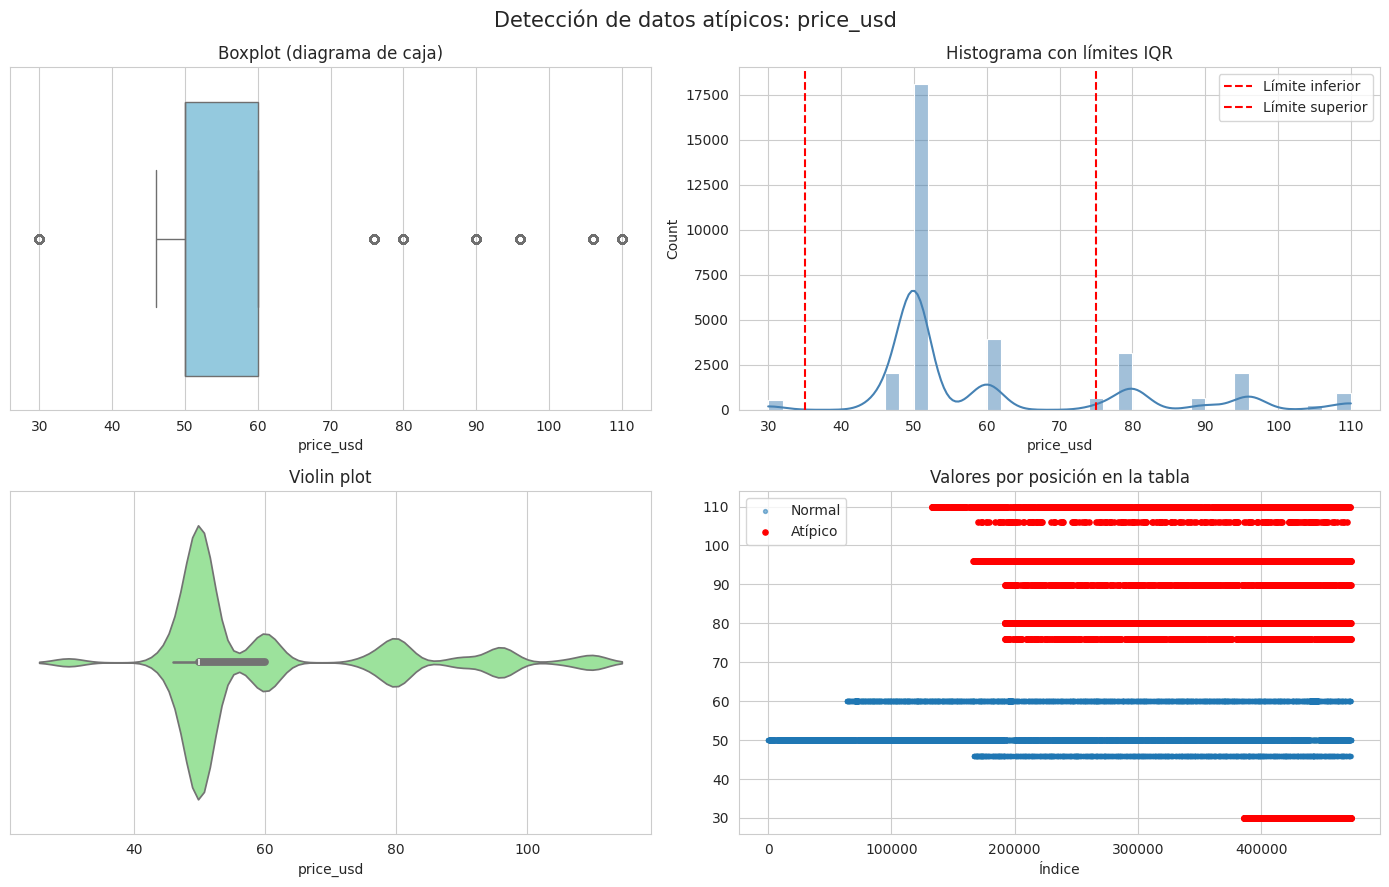


===== margen_bruto_usd =====
Q1 = 30.50 | Q3 = 37.50 | IQR = 7.00
Rango normal: de 20.00 a 48.00
Datos atípicos encontrados: 7712 (23.87% del total)


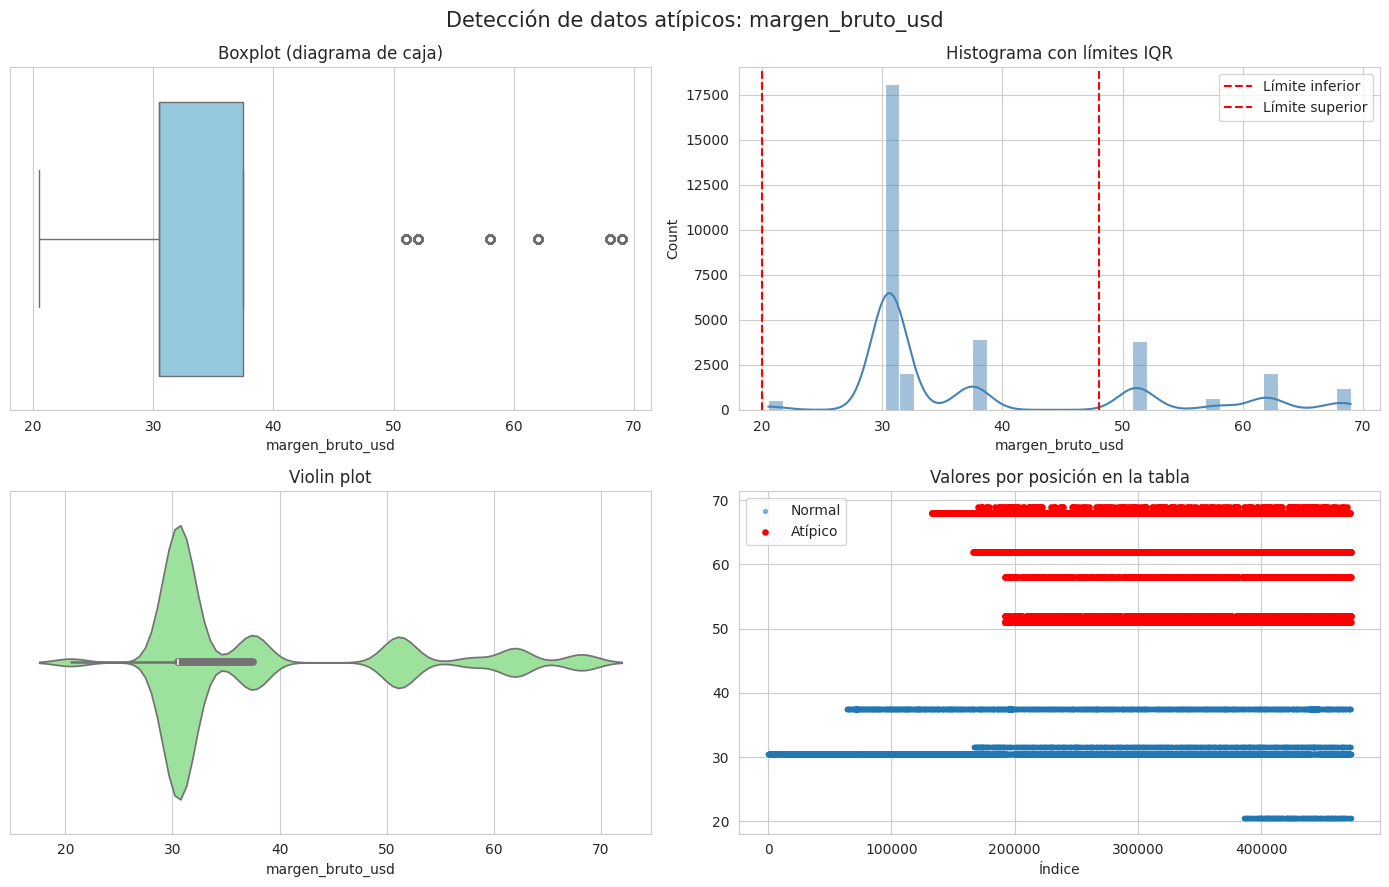

,website_session_id,created_at_sesion,user_id,is_repeat_session,utm_source,utm_campaign,utm_content,device_type,http_referer,order_id,created_at_pedido,primary_product_id,items_purchased,price_usd,cogs_usd,margen_bruto_usd,compra
132875,132876,2013-09-25 08:32:53,116186,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com,7300,2013-09-25 08:49:13,1,2,109.98,41.98,68.0,1
132964,132965,2013-09-25 12:38:52,116266,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com,7302,2013-09-25 12:50:39,1,2,109.98,41.98,68.0,1
133098,133099,2013-09-25 17:15:23,116378,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com,7310,2013-09-25 17:30:15,1,2,109.98,41.98,68.0,1
133587,133588,2013-09-27 01:25:17,103416,1,NaN,NaN,NaN,desktop,NaN,7352,2013-09-27 01:40:13,2,2,109.98,41.98,68.0,1
133995,133996,2013-09-28 10:07:52,88820,1,NaN,NaN,NaN,desktop,NaN,7376,2013-09-28 10:21:27,1,2,109.98,41.98,68.0,1


In [24]:
# Ejecutar la función sobre las variables numéricas
outliers = identify_outliers_iqr(df_compras, num_vars)

# Ver los registros atípicos de price_usd
outliers['price_usd'].head()

In [25]:
# Imprimir los outliers_iqr
outliers

{'price_usd':         website_session_id   created_at_sesion  user_id  is_repeat_session  \
 132875              132876 2013-09-25 08:32:53   116186                  0   
 132964              132965 2013-09-25 12:38:52   116266                  0   
 133098              133099 2013-09-25 17:15:23   116378                  0   
 133587              133588 2013-09-27 01:25:17   103416                  1   
 133995              133996 2013-09-28 10:07:52    88820                  1   
 ...                    ...                 ...      ...                ...   
 472729              472730 2015-03-19 00:26:25   394207                  0   
 472753              472754 2015-03-19 01:30:14   365383                  1   
 472797              472798 2015-03-19 03:59:33   394257                  0   
 472808              472809 2015-03-19 05:09:46   394268                  0   
 472813              472814 2015-03-19 05:16:14   394273                  0   
 
        utm_source utm_campaign utm_c

### Informe final AEDA

In [26]:
# Hacemos otro AEDA para comprobar si quedan problemas de datos ausentes o duplicados

muestra_ok = df_no_dup.sample(n=min(25000, len(df_no_dup)), random_state=42)

profileOK = ProfileReport(muestra_ok[columnas_aeda], title="AEDA_Maven_OK",
                        correlations={
    'auto': {'calculate': False},
    'pearson': {'calculate': False},
    'spearman': {'calculate': False},
    'kendall': {'calculate': False},
    'phi_k': {'calculate': False},
    'cramers': {'calculate': False}
    },
                        explorative=True)

profileOK.to_file("AEDA_Maven_OK.html")
profileOK.to_notebook_iframe()


/usr/local/lib/python3.13/dist-packages/ydata_profiling/utils/dataframe.py:137: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.rename(columns={"index": "df_index"}, inplace=True)


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 14/14 [00:01<00:00,  9.04it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [27]:
# Comprobar que no quedan sesiones duplicadas
print("Sesiones con ID repetido:", df_no_dup['website_session_id'].duplicated().sum())

# Comprobar que no hay filas completamente duplicadas
print("Filas duplicadas:", df_no_dup.duplicated().sum())

# Comprobar el número de sesiones y pedidos
print("Número de sesiones:", len(df_no_dup))
print("Número de pedidos:", df_no_dup['compra'].sum())


Sesiones con ID repetido: 0
Filas duplicadas: 0
Número de sesiones: 472871
Número de pedidos: 32313


In [28]:
# Guardar el dataset limpio en formato Excel
df_no_dup.to_excel('MavenOK.xlsx', index=False)

## Tasa de conversión

### Porcentaje de sesiones web que terminan en una compra

In [29]:
# Número total de sesiones
n_sesiones = len(df_no_dup)

# Número de sesiones que han generado una compra
n_compras = df_no_dup['compra'].sum()

# Tasa de conversión
tasa_conversion = n_compras / n_sesiones * 100

print(f"Número total de sesiones: {n_sesiones}")
print(f"Número de sesiones con compra: {n_compras}")
print(f"Tasa de conversión: {tasa_conversion:.2f}%")


Número total de sesiones: 472871
Número de sesiones con compra: 32313
Tasa de conversión: 6.83%


### Tasa de conversión según el tipo de dispositivo

In [30]:
# Agrupar las sesiones por dispositivo.
tabla_dispositivo = (df_no_dup.groupby('device_type')
                    .agg(sesiones=('website_session_id', 'count'),
                         compras=('compra', 'sum'))
                    .reset_index())

# Tasa de conversión de cada dispositivo.
tabla_dispositivo['conversion_%'] = tabla_dispositivo['compras'] / tabla_dispositivo['sesiones'] * 100

display(tabla_dispositivo.round(2))


,device_type,sesiones,compras,conversion_%
0,desktop,327027,27805,8.50
1,mobile,145844,4508,3.09


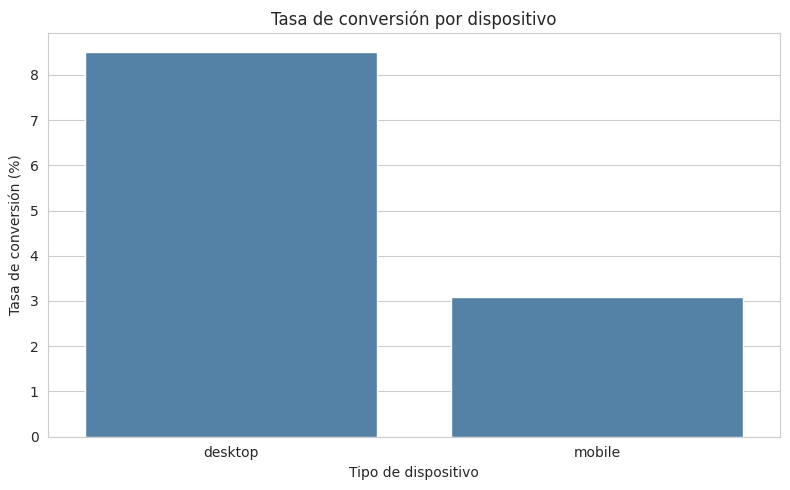

In [31]:
plt.figure(figsize=(8, 5))

sns.barplot(data=tabla_dispositivo, x='device_type', y='conversion_%', color='steelblue')

plt.title('Tasa de conversión por dispositivo')
plt.xlabel('Tipo de dispositivo')
plt.ylabel('Tasa de conversión (%)')

plt.tight_layout()
plt.show()

## Valor de vida del cliente (CLV)


### Cálculo del CLV histórico medio

In [32]:
# Calculamos el valor histórico generado por cada cliente

# Seleccionar únicamente las sesiones con compra
df_compras = df_no_dup[df_no_dup['compra'] == 1].copy()

# Agrupar los pedidos por cliente
tabla_clientes = (df_compras.groupby('user_id')
                  .agg(n_compras=('order_id', 'count'),
                       ingresos_total=('price_usd', 'sum'),
                       margen_total=('margen_bruto_usd', 'sum'))
                  .reset_index())

# CLV histórico medio a partir del margen bruto
clv_medio = tabla_clientes['margen_total'].mean()

print("Número de clientes:", len(tabla_clientes))
print(f"CLV histórico medio: {clv_medio:.2f} USD")

display(tabla_clientes.head(10))


Número de clientes: 31696
CLV histórico medio: 38.37 USD


,user_id,n_compras,ingresos_total,margen_total
0,13,1,49.99,30.5
1,20,1,49.99,30.5
2,59,1,49.99,30.5
3,104,1,49.99,30.5
4,147,1,49.99,30.5
5,160,1,49.99,30.5
6,167,1,49.99,30.5
7,177,1,49.99,30.5
8,210,1,49.99,30.5
9,232,1,49.99,30.5


### CLV histórico según el número de compras por cliente

In [33]:
# Agrupar los clientes según su número de compras
tabla_frecuencia = (tabla_clientes.groupby('n_compras')
                    .agg(clientes=('user_id', 'count'),
                         clv_medio=('margen_total', 'mean'))
                    .reset_index())

# Calcular el porcentaje de clientes de cada grupo
tabla_frecuencia['porcentaje_clientes'] = tabla_frecuencia['clientes'] / len(tabla_clientes) * 100

display(tabla_frecuencia.round(2))


,n_compras,clientes,clv_medio,porcentaje_clientes
0,1,31105,37.59,98.14
1,2,565,77.70,1.78
2,3,26,112.27,0.08


### Distribución del CLV histórico

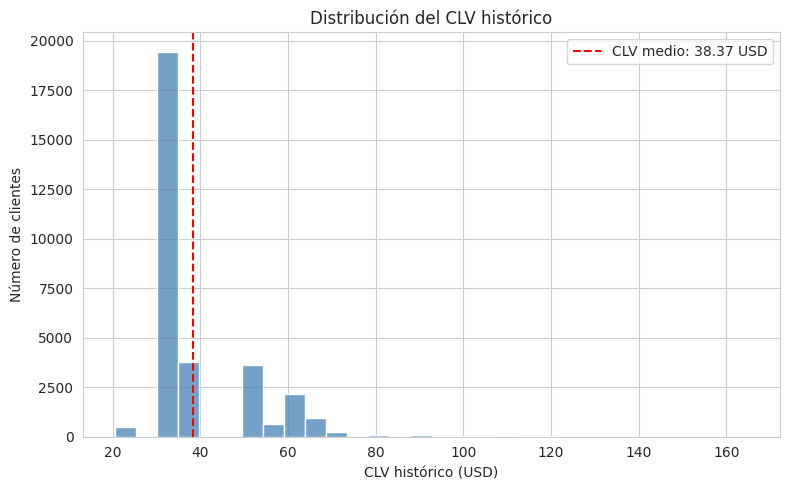

In [34]:
plt.figure(figsize=(8, 5))

sns.histplot(data=tabla_clientes, x='margen_total', bins=30, color='steelblue')

plt.axvline(clv_medio, color='red', linestyle='--',
            label=f'CLV medio: {clv_medio:.2f} USD')

plt.title('Distribución del CLV histórico')
plt.xlabel('CLV histórico (USD)')
plt.ylabel('Número de clientes')
plt.legend()

plt.tight_layout()
plt.show()


## Tasa de retención

### Cálculo de la recompra a 12 meses

In [35]:
# Seleccionar las sesiones con compra y ordenarlas por fecha
df_compras = df_no_dup[df_no_dup['compra'] == 1].copy()
df_compras = df_compras.sort_values(['user_id', 'created_at_pedido'])

# Numerar las compras de cada cliente
df_compras['numero_compra'] = df_compras.groupby('user_id').cumcount() + 1

# Identificar la primera compra de cada cliente
primera_compra = (df_compras[df_compras['numero_compra'] == 1]
    [['user_id', 'created_at_pedido']]
    .rename(columns={'created_at_pedido': 'primera_compra'}))

# Identificar la segunda compra de cada cliente
segunda_compra = (df_compras[df_compras['numero_compra'] == 2]
    [['user_id', 'created_at_pedido']]
    .rename(columns={'created_at_pedido': 'segunda_compra'}))

# Unir las dos tablas, conservando todos los clientes compradores
tabla_clientes_12m = primera_compra.merge(segunda_compra, on='user_id', how='left')

# Calcular la fecha límite de los 12 meses
tabla_clientes_12m['fecha_limite'] = (tabla_clientes_12m['primera_compra'] + pd.DateOffset(months=12))

# Seleccionar únicamente los clientes con 12 meses completos de seguimiento
fecha_fin = df_compras['created_at_pedido'].max()

tabla_clientes_12m = tabla_clientes_12m[tabla_clientes_12m['fecha_limite'] <= fecha_fin].copy()

# Identificar los clientes que vuelven a comprar dentro de los 12 meses
tabla_clientes_12m['recompra_12m'] = (tabla_clientes_12m['segunda_compra'].notna() & (tabla_clientes_12m['segunda_compra'] <=
     tabla_clientes_12m['fecha_limite']))

# Crear una columna con el mes de la primera compra
tabla_clientes_12m['periodo'] = (tabla_clientes_12m['primera_compra'].dt.to_period('M'))

# Agrupar los clientes según el mes de su primera compra
tabla_retencion = (tabla_clientes_12m.groupby('periodo').agg(clientes_inicio=('user_id', 'count'),
         clientes_retenidos=('recompra_12m', 'sum')))

# Calcular la tasa de recompra a 12 meses de cada grupo
tabla_retencion['retencion_%'] = (tabla_retencion['clientes_retenidos'] /tabla_retencion['clientes_inicio'] * 100)


display(tabla_retencion.round(2))


,clientes_inicio,clientes_retenidos,retencion_%
periodo,,,
2012-03,60,0,0.00
2012-04,99,0,0.00
2012-05,108,0,0.00
2012-06,139,2,1.44
2012-07,168,0,0.00
2012-08,227,2,0.88
2012-09,286,4,1.40
2012-10,368,4,1.09
2012-11,612,4,0.65


### Tasa de recompra a 12 meses

In [36]:
# Solo se incluyen clientes con 12 meses completos de seguimiento
retencion_media = (
    tabla_retencion['clientes_retenidos'].sum() /
    tabla_retencion['clientes_inicio'].sum() * 100)

print(f"Tasa de recompra a 12 meses: {retencion_media:.2f}%")
print("Clientes analizados:", tabla_retencion['clientes_inicio'].sum())
print("Clientes que vuelven a comprar:", tabla_retencion['clientes_retenidos'].sum())
print("Meses de primera compra analizados:", len(tabla_retencion))



Tasa de recompra a 12 meses: 1.57%
Clientes analizados: 12494
Clientes que vuelven a comprar: 196
Meses de primera compra analizados: 25


### Evolución de la recompra a 12 meses

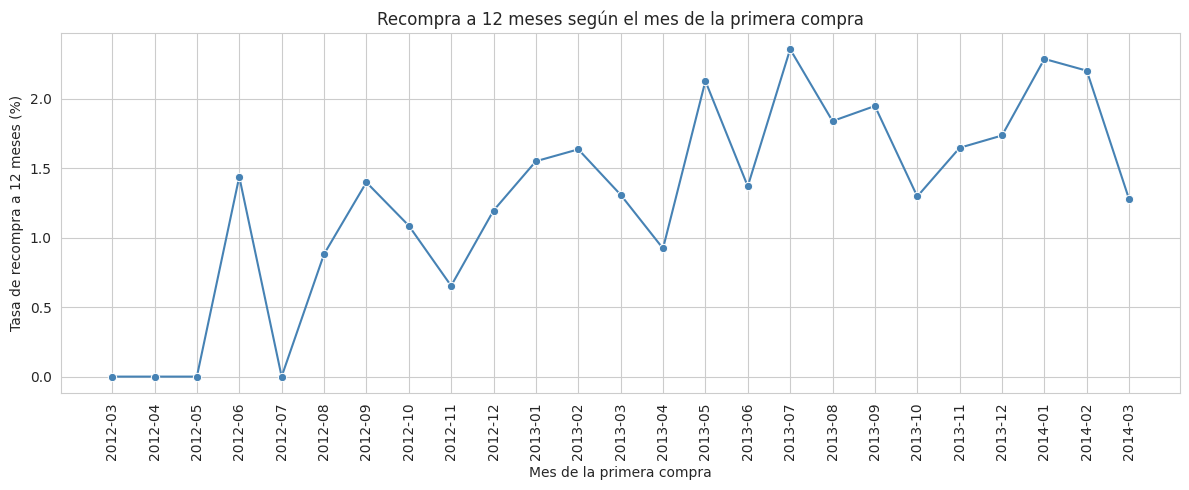

In [37]:
plt.figure(figsize=(12, 5))

sns.lineplot(x=tabla_retencion.index.astype(str),
             y=tabla_retencion['retencion_%'],
             marker='o', color='steelblue')

plt.title('Recompra a 12 meses según el mes de la primera compra')
plt.xlabel('Mes de la primera compra')
plt.ylabel('Tasa de recompra a 12 meses (%)')
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()


## Resumen de los indicadores

In [38]:
resumen_crm = pd.DataFrame({
    'Indicador': ['Tasa de conversión',
                  'CLV histórico medio',
                  'Tasa de retención a 12 meses'],
    'Valor': [f'{tasa_conversion:.2f}%',
              f'{clv_medio:.2f} USD',
              f'{retencion_media:.2f}%']
})

# Mostrar la tabla
display(resumen_crm)


,Indicador,Valor
0,Tasa de conversión,6.83%
1,CLV histórico medio,38.37 USD
2,Tasa de retención a 12 meses,1.57%
